<div style="text-align: center;">
    <h1>Watt’s Next? Predicting EV Range and Mapping Adoption in Washington State</h1>
</div>

## **Done By**

- **Abhishek Rithik Origanti**
- **Matheshwara Annamalai Senthilkumar**


## **Introduction**
Electric vehicles (EVs) are a huge change in the transportation industry. They help solve important world problems like climate change, air pollution, and our overuse of fossil fuels. As more people around the world look for environmentally friendly options, it becomes more important to understand how EVs are adopted, how well they work, and what kind of infrastructure they need. Data science is very important to this work because it can find hidden patterns and give us useful information.

EVs are very important for society because they help us reach our lofty climate goals and cut down on greenhouse gas emissions. A lot of money is being put into EV technology and infrastructure by governments and businesses. This is providing a lot of data that can help people make better decisions. For example, to effectively scale up EV adoption, we need to know answers to questions like "Which regions adopt EVs at a higher rate?" or "What factors affect electric range?"

Reading EV data is a fun and interesting task in the field of data science. EV data is very varied and includes things like electric range, model year, manufacturer, regional trends, and more. It takes a mix of statistical analysis, predictive modelling, and machine learning to look at this data, which shows how powerful and flexible current data science techniques are.

### **This tutorial demonstrates how data science can:**

**i.)** **Analyze EV Performance and Adoption:** Use descriptive statistics to explore key metrics such as electric range, identifying trends over time and across manufacturers.

**ii.)** **Test Hypotheses:** Validate assumptions about EV adoption and performance, such as whether Battery Electric Vehicles (BEVs) outperform Plug-in Hybrid Electric Vehicles (PHEVs), or if adoption patterns vary significantly by region.

**iii.)** **Build Predictive Models:** Forecast electric range, classify vehicles, and predict eligibility for Clean Air Vehicle (CAFV) incentives, leveraging machine learning to make informed predictions.

**iv.)** **Map Adoption:** Visualize where EVs are registered across Washington State using geospatial heatmaps.

The intersection of EV technology and data science is not only exciting but also highly impactful. By applying these techniques, this tutorial highlights how data-driven insights can explain how EV range is changing and show where EV ownership is concentrated. This makes the topic critical both for advancing sustainable transportation and for showcasing the practical applications of data science in solving real-world challenges.

### Table of Contents

1. [Data Preparation](#data-preparation)  
   - [Importing Libraries and Datasets](#importing-libraries-and-datasets)  
   - [Data Cleaning and Preprocessing](#data-cleaning-and-preprocessing)  
   - [Exploratory Data Analysis (EDA)](#exploratory-data-analysis-eda)  
   - [Descriptive Statistics (Mean, Median, Mode)](#descriptive-statistics-mean-median-mode)  

2. [Hypothesis Testing](#hypothesis-testing)  
   - [t-Test / ANOVA](#t-test-anova)   
   - [Chi-Square Test / ANOVA](#chi-square-test-anova)  

3. [Predictive Modeling](#predictive-modeling)  
   - [Predicting Electric Range](#predicting-electric-range)    
   - [Predicting CAFV Eligibility](#predicting-cafv-eligibility)  

4. [Classification Models - Logistic Regression](#classification-models)  
   - [Classifying BEVs vs. PHEVs](#classifying-bevs-vs-phevs-logistic-regression)  

5. [Geospatial Analysis](#geospatial-analysis)  
   - [Mapping EV Registration Density](#mapping-ev-registration-density)  

6. [Conclusions and Insights](#conclusions-and-insights)  

7. [References and Resources](#references-and-resources)


## Data Preparation

### Importing Libraries and Datasets

In this section, we’ll gather all the data we need for our analysis from Kaggle. Using Python, we’ll load the data from CSV file to make sure we have all the relevant details for our study. We’ll begin by importing the necessary Python libraries that will help us collect, clean, and analyze the data. These tools will make it easier to process the data and get it ready for the next steps in our project. By the end of this section, we’ll have a clean and organized dataset, set to dive into the exploration and modeling phases.

In [ ]:
pip install seaborn

In [ ]:
!pip install scikit-learn

In [ ]:
!pip install statsmodels

In [ ]:
!pip install imblearn

In [ ]:
!pip install geopandas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, classification_report, confusion_matrix
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from imblearn.over_sampling import SMOTE
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from scipy import stats
import plotly.graph_objects as go
import geopandas as gpd
from shapely.geometry import Point
import folium
from folium.plugins import HeatMap
from IPython.display import display
from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency
from sklearn.model_selection import learning_curve

#### **Dataset Overview**

##### **Understanding the Dataset**

The dataset contains **216,772 rows** across **17 columns**, offering a detailed snapshot of electric vehicles (EVs) manufactured between **1999 and 2025**. Each column provides a piece of the puzzle, but not all are equally relevant to our analysis. Below, we’ll walk through what each column represents and identify the ones most valuable for extracting meaningful insights.

---

#### **What Each Column Represents**

1. **VIN (1-10)**:  
   - **Description**: A partial Vehicle Identification Number unique to each vehicle.  
   - **Relevance**: While useful for administrative purposes, it doesn’t contribute to analyzing EV trends or predicting performance.  
   - **Action**: Can be removed from the analysis.

2. **County, City, State, Postal Code**:  
   - **Description**: Geographic details of where vehicles are registered.  
   - **Relevance**: Critical for understanding **regional adoption trends** and planning charging infrastructure.  
   - **Action**: Retain for regional analysis and infrastructure planning.

3. **Model Year**:  
   - **Description**: Indicates the year the vehicle was manufactured.  
   - **Relevance**: Essential for analyzing **trends over time** and forecasting future performance.  
   - **Action**: Retain for trend analysis.

4. **Make and Model**:  
   - **Description**: Specifies the manufacturer and model of each vehicle.  
   - **Relevance**: Useful for identifying **performance differences** across brands and models.  
   - **Action**: Retain for manufacturer and model analysis.

5. **Electric Vehicle Type**:  
   - **Description**: Specifies whether the vehicle is a **Battery Electric Vehicle (BEV)** or a **Plug-in Hybrid Electric Vehicle (PHEV)**.  
   - **Relevance**: Central to hypothesis testing and classification models.  
   - **Action**: Retain for type-based analysis.

6. **Electric Range**:  
   - **Description**: Maximum range the vehicle can travel on electric power alone.  
   - **Relevance**: A key metric for **predictive modeling**, and performance evaluation.  
   - **Action**: Retain for range-based insights.

7. **Clean Alternative Fuel Vehicle (CAFV) Eligibility**:  
   - **Description**: Indicates whether the vehicle qualifies for clean air incentives.  
   - **Relevance**: Perfect for building models to predict eligibility and policy impact analysis.  
   - **Action**: Retain for eligibility prediction.

8. **Vehicle Location**:  
   - **Description**: May include geographic coordinates of vehicle registration.  
   - **Relevance**: Useful for mapping **EV adoption** and planning infrastructure like charging stations.  
   - **Action**: Retain for spatial analysis.

---

#### **Columns to Exclude**
Based on the analysis, columns like **VIN (1-10)** may be excluded to focus on insights that directly relate to EV adoption, performance, and infrastructure planning.

---

This dataset offers an incredible opportunity to uncover **regional trends**, **predict performance**, and support **sustainable infrastructure development**. By focusing on the most relevant columns, we can streamline our analysis and derive actionable insights efficiently.

In [2]:
df = pd.read_csv("D:\College\Data Sets\DS Data sets\Electric_Vehicle_Population_Data-2.csv")
df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,1N4AZ0CP8D,King,Shoreline,WA,98177.0,2013,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,75.0,0.0,32.0,125450447,POINT (-122.36498 47.72238),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303302e+10
1,5YJSA1E45K,King,Seattle,WA,98112.0,2019,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,270.0,0.0,43.0,101662900,POINT (-122.30207 47.64085),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303301e+10
2,WVGUNPE28M,Kitsap,Olalla,WA,98359.0,2021,VOLKSWAGEN,ID.4,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,0.0,26.0,272118717,POINT (-122.54729 47.42602),PUGET SOUND ENERGY INC,5.303509e+10
3,JTDKARFP6H,Thurston,Olympia,WA,98501.0,2017,TOYOTA,PRIUS PRIME,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,25.0,0.0,22.0,349372929,POINT (-122.89166 47.03956),PUGET SOUND ENERGY INC,5.306701e+10
4,1FADP5CU9G,Thurston,Olympia,WA,98506.0,2016,FORD,C-MAX,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,19.0,0.0,22.0,171625653,POINT (-122.87741 47.05997),PUGET SOUND ENERGY INC,5.306701e+10


In [3]:
df.shape

(216772, 17)

We decided to drop the columns VIN (1-10), Base MSRP, DOL Vehicle ID, Electric Utility, Legislative District, and 2020 Census Tract because they don’t contribute meaningful insights to our analysis

In [4]:
# List of columns to drop
columns_to_drop = ['VIN (1-10)', 'Base MSRP', 'DOL Vehicle ID', 'Electric Utility', 'Legislative District','2020 Census Tract']
# Drop the specified columns
ndf = df.drop(columns=columns_to_drop)
ndf.head()

,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Vehicle Location
0,King,Shoreline,WA,98177.0,2013,NISSAN,LEAF,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,75.0,POINT (-122.36498 47.72238)
1,King,Seattle,WA,98112.0,2019,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,270.0,POINT (-122.30207 47.64085)
2,Kitsap,Olalla,WA,98359.0,2021,VOLKSWAGEN,ID.4,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,POINT (-122.54729 47.42602)
3,Thurston,Olympia,WA,98501.0,2017,TOYOTA,PRIUS PRIME,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,25.0,POINT (-122.89166 47.03956)
4,Thurston,Olympia,WA,98506.0,2016,FORD,C-MAX,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,19.0,POINT (-122.87741 47.05997)


### Data Cleaning and Preprocessing

In our data preprocessing, we begin by addressing missing values, as they can significantly impact the quality of our analysis. We calculate the extent of missing values across each column to understand their distribution and potential impact.

In [5]:
# Count the number of missing values in each column
missing_counts = ndf.isnull().sum()
print("Missing Counts:\n", missing_counts)

Missing Counts:
 County                                                5
City                                                  5
State                                                 0
Postal Code                                           5
Model Year                                            0
Make                                                  0
Model                                                 0
Electric Vehicle Type                                 0
Clean Alternative Fuel Vehicle (CAFV) Eligibility     0
Electric Range                                       19
Vehicle Location                                     11
dtype: int64


For the column Electric Range, we observe that some entries are null. Since these missing values (Electric range, City, Postal Code, County and Vehicle Location) appear to be **completely at random,** we remove rows where the Electric Range is null to maintain the integrity of our analysis, as this column is a critical variable for prediction, and performance evaluation.

---

The provided code snippet focuses on preprocessing the Electric Range column to ensure the data is clean and reliable for analysis. Initially, we are converting the Electric Range column to numeric, where any invalid or non-numeric entries are coerced to NaN. This step ensures the column contains only valid numeric values, avoiding errors during subsequent operations.

Next, the code counts the rows where the Electric Range is exactly 0.0. This is done to identify invalid entries that may represent missing or meaningless data. The explicit check for 0.0 ensures no ambiguity with NaN values or other unexpected formats.

In [6]:
# Count rows where 'Electric Range' is exactly 0.0 (ensure there are no issues with NaN or unexpected formats)
zero_electric_range_count = ndf[ndf['Electric Range'] == 0.0].shape[0]
print(f"Number of rows with Electric Range = 0.0: {zero_electric_range_count}")

Number of rows with Electric Range = 0.0: 124101


---
The key step in this process is filtering the dataset to remove rows where Electric Range is either 0.0 or NaN. Rows with these values are unlikely to contribute meaningful insights, as they represent vehicles with no electric range, which may not align with the dataset's focus on EV performance and capabilities.

Finally, the updated shape of the dataset is printed to verify that rows with invalid or missing values have been successfully removed. This ensures the remaining data is accurate and ready for analysis, laying a strong foundation for reliable results in subsequent modeling and statistical evaluations.

In [7]:
# Remove rows where 'Electric Range' is 0.0 or NaN
ndf = ndf[(ndf['Electric Range'] != 0.0) & (ndf['Electric Range'].notna())]

# Verify by checking the shape or first few rows
print(f"Data after removing rows with Electric Range = 0.0 or NaN: {ndf.shape}")

Data after removing rows with Electric Range = 0.0 or NaN: (92652, 11)


---
In data preprocessing, scaling numerical features is an essential step, especially when preparing data for machine learning models. By scaling, we ensure that all numerical values are on a similar range, which can improve how well models perform and make their behavior more stable.

One common way to scale data is by using the MinMaxScaler from the sklearn.preprocessing module. This tool transforms data so that all values fall within a specified range, typically between 0 and 1. It works by applying a straightforward formula:

$X' = \frac{X - \text{min}(X)}{\text{max}(X) - \text{min}(X)}$

Here, $X$ is the original value, and $X’$ is the scaled version. 

Scaling is especially important in machine learning because some algorithms are very sensitive to the range of feature values. For instance:
	•	In gradient-based optimization methods, like those used in neural networks, features with vastly different scales can slow down the learning process.
	•	For distance-based models, such as k-Nearest Neighbors or clustering algorithms, inconsistent feature scales can distort the calculations, leading to incorrect results.

By using techniques like MinMax scaling, we can standardize data, making sure each feature contributes meaningfully to the model and improving the overall effectiveness of our machine learning pipeline.

---

In [8]:
# Create a copy of the original DataFrame to leave the original unchanged
ndf_scaled = ndf.copy()

# Initialize the MinMaxScaler
scaler = MinMaxScaler()

# Reshape 'Electric Range' as 2D array to fit the scaler
ndf_scaled['Electric Range'] = scaler.fit_transform(ndf_scaled[['Electric Range']])

# Verify the scaling in the new DataFrame
print(ndf_scaled[['Electric Range']].head())

# Verify min and max after scaling in the new DataFrame
print("Min in scaled DataFrame:", ndf_scaled['Electric Range'].min())
print("Max in scaled DataFrame:", ndf_scaled['Electric Range'].max())

   Electric Range
0        0.208459
1        0.797583
3        0.057402
4        0.039275
5        0.785498
Min in scaled DataFrame: 0.0
Max in scaled DataFrame: 1.0


---
Transforming categorical data into numerical format is an essential part of data preprocessing, especially when preparing a dataset for machine learning. Let’s walk through a practical example to understand how to do this step-by-step.

Here we have a column named **Clean Alternative Fuel Vehicle (CAFV) Eligibility** in our dataset. This column contains information about whether a vehicle is eligible for clean alternative fuel incentives. The values might look something like this:

- “Clean Alternative Fuel Vehicle Eligible”  
- “Not eligible due to low battery range”  
- “Eligibility unknown as battery range has not been determined”  

Machine learning algorithms often struggle with text-based categorical data. To make this column usable, we need to convert these text categories into numerical values. Hence we map each category:

- **1** for vehicles eligible for clean fuel incentives.  
- **0** for vehicles not eligible due to low battery range.  
- **-1** (optional) for cases where eligibility is unknown.  

In [9]:
# Convert 'Clean Alternative Fuel Vehicle (CAFV) Eligibility' to categorical (binary)
ndf_scaled['Clean Alternative Fuel Vehicle (CAFV) Eligibility'] = ndf_scaled['Clean Alternative Fuel Vehicle (CAFV) Eligibility'].map({
    'Clean Alternative Fuel Vehicle Eligible': 1,
    'Not eligible due to low battery range': 0,
    'Eligibility unknown as battery range has not been determined': -1  # Optional: if you want to handle unknown eligibility
})

ndf_scaled[['Clean Alternative Fuel Vehicle (CAFV) Eligibility']].head()

,Clean Alternative Fuel Vehicle (CAFV) Eligibility
0,1
1,1
3,0
4,0
5,1


Now that we’ve completed the ETL (Extract, Transform, Load) process and prepared our data, it’s time to clean up any remaining missing values. Removing these ensures that our dataset is complete and ready for analysis or modeling.

In [10]:
df_cleaned = ndf_scaled.dropna()

In [11]:
# Count the number of missing values in each column
missing_counts = df_cleaned.isnull().sum()
print("\nMissing Counts:\n", missing_counts)



Missing Counts:
 County                                               0
City                                                 0
State                                                0
Postal Code                                          0
Model Year                                           0
Make                                                 0
Model                                                0
Electric Vehicle Type                                0
Clean Alternative Fuel Vehicle (CAFV) Eligibility    0
Electric Range                                       0
Vehicle Location                                     0
dtype: int64


---
The code saves the DataFrame df_cleaned to a CSV file named cleaned.csv. The parameter index=False ensures that the row indices are not included as an extra column in the output file.

---

In [12]:
# Assuming you have a DataFrame called 'df'
df_cleaned.to_csv('cleaned.csv', index=False)

### Exploratory Data Analysis (EDA)

We analyzed the relationships between Electric Range, Model Year, and Manufacturer to uncover trends in EV development and market performance. Here's what we found:

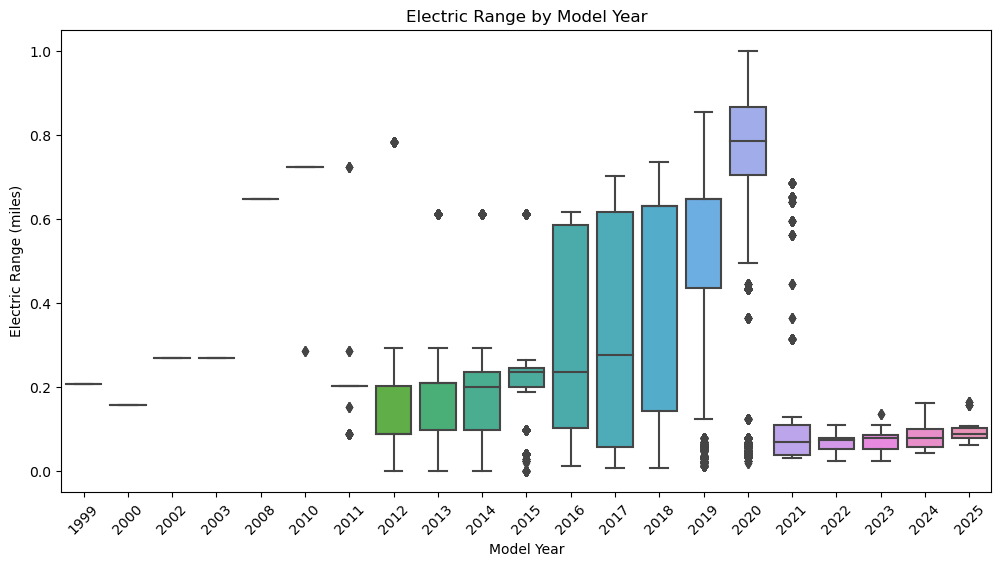

In [13]:
# Assuming the data is already in a DataFrame named 'data'
# Convert 'Electric Range' to numeric, assuming it's in miles
# Load the dataset
data = pd.read_csv(r'C:\Users\jermi\cleaned.csv')

data.loc[:, 'Electric Range'] = pd.to_numeric(data['Electric Range'], errors='coerce')

# Relationship between Model Year and Electric Range
plt.figure(figsize=(12, 6))
sns.boxplot(x='Model Year', y='Electric Range', data=data)
plt.title('Electric Range by Model Year')
plt.xlabel('Model Year')
plt.ylabel('Electric Range (miles)')
plt.xticks(rotation=45)
plt.show()

#### Electric Range by Model Year
- A boxplot shows electric ranges improving over time, reflecting advancements in EV technology.

- Recent years display wider variability, with options ranging from short-range affordable EVs to premium long-range vehicles.

- Outliers indicate unique vehicles with exceptionally high or low ranges for their time.

The boxplot visualizes the distribution of Electric Range by Model Year, with a figure size of 12x6 inches for clarity. Each year is represented in distinct colors to differentiate groups easily. The boxes show the interquartile range (middle 50% of data), with whiskers extending to 1.5 times the IQR and outliers displayed as dots. The x-axis (Model Year) labels are rotated 45 degrees for readability, and the y-axis represents the Electric Range in miles.

We chose a boxplot because it effectively summarizes the distribution of data, highlighting medians, variability, and outliers within each model year. Unlike line or bar charts, which focus on averages or trends, boxplots allow us to see the spread and detect anomalies, making it ideal for comparing electric range distributions across multiple years. The clean layout and clear labels further enhance its interpretability.

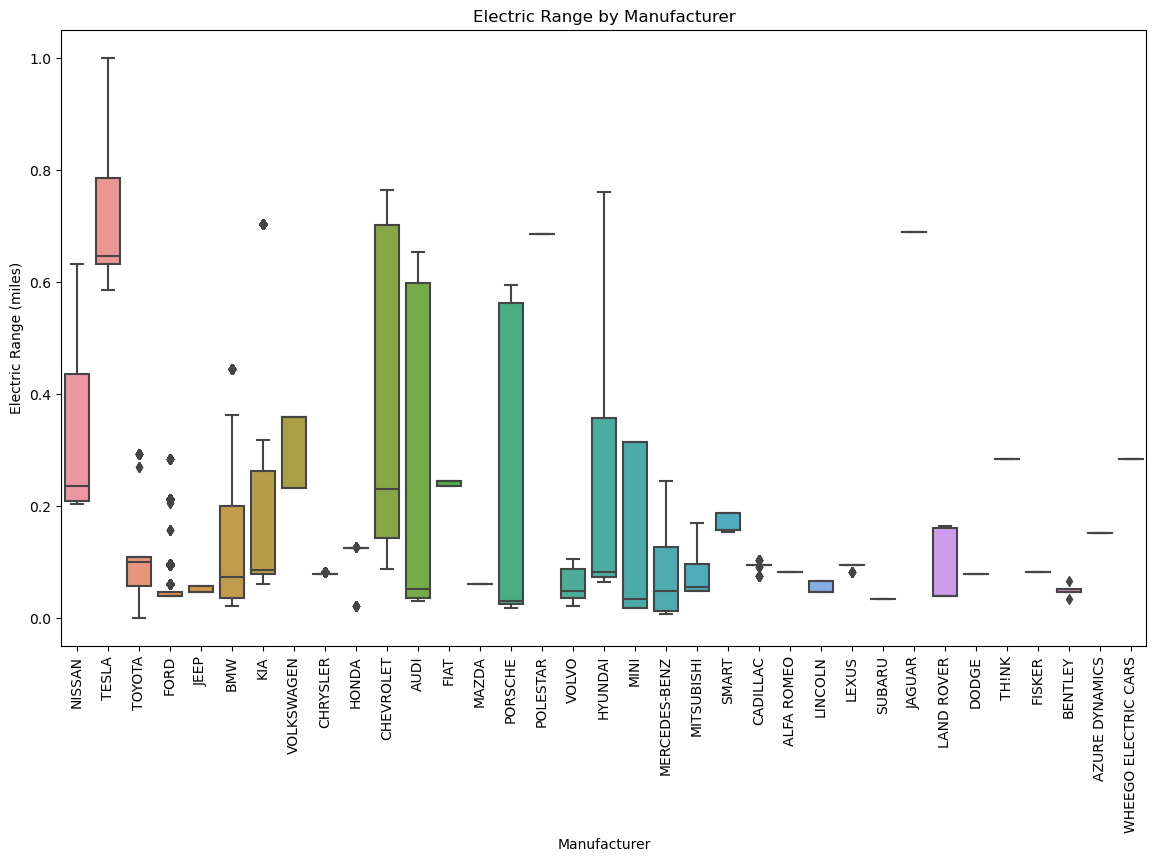

In [14]:
# Relationship between Manufacturer and Electric Range
plt.figure(figsize=(14, 8))
sns.boxplot(x='Make', y='Electric Range', data=data)
plt.title('Electric Range by Manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Electric Range (miles)')
plt.xticks(rotation=90)
plt.show()

#### Electric Range by Manufacturer
• Manufacturers like Tesla consistently deliver high ranges, positioning them as leaders.

• Brands like Toyota and BMW display wider variability, reflecting diverse EV models.

• This highlights how manufacturers differentiate themselves in the market.

---

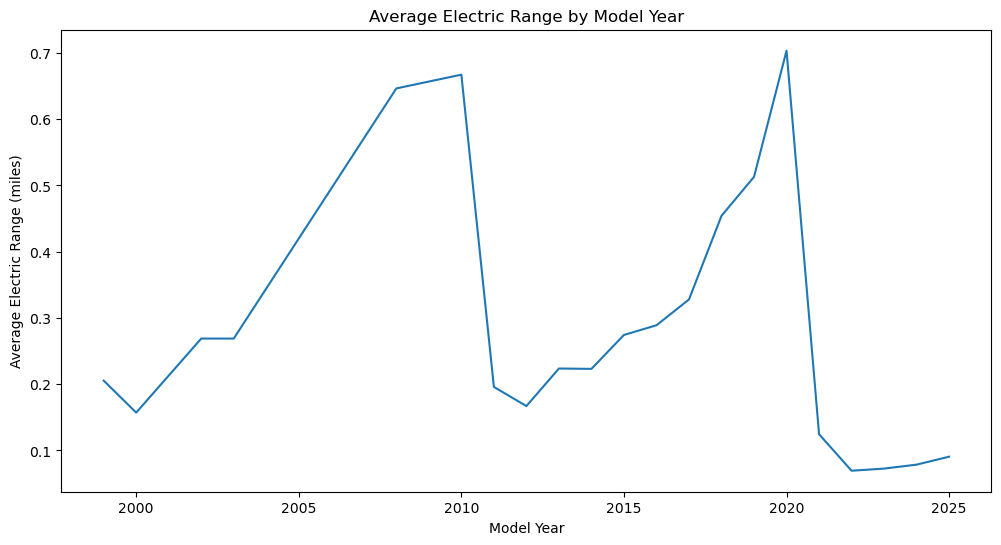

In [15]:
# Calculate average electric range by model year
avg_range_by_year = data.groupby('Model Year')['Electric Range'].mean().reset_index()
plt.figure(figsize=(12, 6))
sns.lineplot(x='Model Year', y='Electric Range', data=avg_range_by_year)
plt.title('Average Electric Range by Model Year')
plt.xlabel('Model Year')
plt.ylabel('Average Electric Range (miles)')
plt.show()

#### Average Electric Range by Model Year
- A line graph shows a general upward trend in average electric range, signaling continuous improvement in EV technology.
 
- Recent dips may result from the introduction of more affordable, short-range EVs.

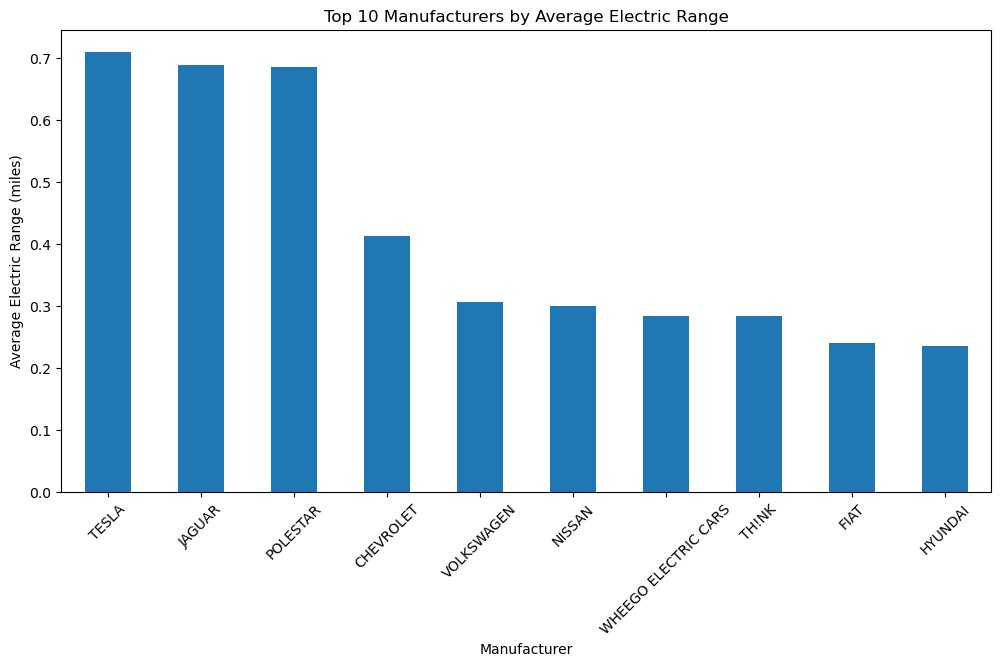

In [16]:
# Top 10 manufacturers by average electric range
top_10_manufacturers = data.groupby('Make')['Electric Range'].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(12, 6))
top_10_manufacturers.plot(kind='bar')
plt.title('Top 10 Manufacturers by Average Electric Range')
plt.xlabel('Manufacturer')
plt.ylabel('Average Electric Range (miles)')
plt.xticks(rotation=45)
plt.show()

#### Top 10 Manufacturers by Average Electric Range
- Tesla, Jaguar, and Polestar lead the market with the highest average electric ranges.

- Other brands like Chevrolet and Volkswagen rank well, showing their commitment to competitive EV offerings.

---
#### Key Insights
- **Technological Progress**: EV ranges have improved significantly over time.

- **Market Diversity**: There’s a growing variety of EVs, from budget-friendly models to premium options.

- **Manufacturer Leadership**: Top brands dominate the market with innovative, long-range EVs.

Our findings showcase how the EV market has evolved and provide insights into the performance and positioning of key players in the industry.

---

### Descriptive Statistics (Mean, Median, Mode)

Let’s take a closer look at the Electric Range column in our dataset to understand its overall behavior and distribution.

In [17]:
# Descriptive statistics for Electric Range
electric_range_mean = df_cleaned['Electric Range'].mean()
electric_range_median = df_cleaned['Electric Range'].median()
electric_range_distribution = df_cleaned['Electric Range'].describe()

print("Electric Range Mean:", electric_range_mean)
print("Electric Range Median:", electric_range_median)
print("\nElectric Range Distribution:\n", electric_range_distribution)

Electric Range Mean: 0.3312337205057345
Electric Range Median: 0.202416918429003

Electric Range Distribution:
 count    92645.000000
mean         0.331234
std          0.298123
min          0.000000
25%          0.072508
50%          0.202417
75%          0.631420
max          1.000000
Name: Electric Range, dtype: float64


---
#### Key Insights:
1. **Mean and Median**:
   - The mean (average) electric range is approximately 0.33. This tells us that, on average, vehicles in our dataset have an electric range near this value on a normalized scale (scaled between 0 and 1).
   - The median, which is the middle value when all ranges are sorted, is 0.20. This is lower than the mean, suggesting that the distribution might be skewed, with a few vehicles having much higher electric ranges.

2. **Distribution Summary**:
   - We analyzed 92,645 vehicles, as shown by the count.
   - The minimum electric range is 0, indicating that some vehicles in the dataset have no electric range at all.
   - The maximum is 1, representing the highest electric range within the normalized scale.
   - The standard deviation (std) is 0.30, showing moderate variability in electric range values.
   - The 25th percentile (0.07), median (0.20), and 75th percentile (0.63) indicate that most vehicles cluster within the lower half of the range, further reinforcing the idea of skewness.

#### What Does This Mean for Our Data?

The majority of vehicles have relatively low electric ranges, with only a few reaching the higher end. This might suggest a significant number of traditional hybrid or low-range electric vehicles in the dataset, while a smaller subset represents fully electric vehicles with larger ranges.

---


Let’s explore the Adoption Rate based on the Clean Alternative Fuel Vehicle (CAFV) Eligibility values in our dataset. This column indicates whether a vehicle is eligible for clean fuel incentives, and we’ll treat it as a measure of adoption for these vehicles.


In [18]:
# Assuming 'Adoption Rate' refers to the 'Clean Alternative Fuel Vehicle (CAFV) Eligibility' values
adoption_rate_mean = df_cleaned['Clean Alternative Fuel Vehicle (CAFV) Eligibility'].mean()
adoption_rate_distribution = df_cleaned['Clean Alternative Fuel Vehicle (CAFV) Eligibility'].value_counts()

print("Adoption Rate Mean:", adoption_rate_mean)
print("\nAdoption Rate Distribution:\n", adoption_rate_distribution)

Adoption Rate Mean: 0.764455718063576

Adoption Rate Distribution:
 1    70823
0    21822
Name: Clean Alternative Fuel Vehicle (CAFV) Eligibility, dtype: int64


---
#### Key Insights:

1. **Mean Adoption Rate**:
   - The mean adoption rate is approximately 0.76. This means that around 76% of the vehicles in our dataset are eligible for clean alternative fuel incentives. This suggests a relatively high rate of adoption for clean fuel vehicles within the dataset.

2. **Adoption Rate Distribution**:
   - **1 (Eligible)**: There are 70,823 vehicles eligible for clean alternative fuel incentives, making up the majority of the dataset.
   - **0 (Not Eligible)**: There are 21,822 vehicles that are not eligible, which is a smaller portion.


The data shows that 76% of the vehicles are eligible for clean alternative fuel incentives, indicating a high adoption rate of clean fuel vehicles. However, the remaining 24% are not eligible, suggesting that a significant portion of vehicles still fall outside the clean fuel criteria, possibly due to factors like lower battery ranges or older models. This highlights strong adoption but also points to areas where further growth or incentives could be focused.

---

In [19]:
# Frequency analysis for registrations by County and City
county_frequency = df_cleaned['County'].value_counts()
city_frequency = df_cleaned['City'].value_counts()

print("\nEV Registrations by County:\n", county_frequency.head())
print("\nEV Registrations by City:\n", city_frequency.head())


EV Registrations by County:
 King         44618
Snohomish     9636
Pierce        7401
Clark         6019
Thurston      3715
Name: County, dtype: int64

EV Registrations by City:
 Seattle      15347
Bellevue      3769
Vancouver     3663
Renton        2709
Redmond       2634
Name: City, dtype: int64


#### Key Insights:

1. **EV Registrations by County**:
   - **King County** has the highest number of EV registrations with 44,618 vehicles, which is by far the largest in the dataset.
   - **Snohomish County** follows with 9,636 registrations, and other counties like **Pierce, Clark, and Thurston** have notably fewer registrations, with values ranging from 3,715 to 7,401.
   
   This suggests that urban or more populous counties, particularly King County, have the highest adoption rates of EVs.

2. **EV Registrations by City**:
   - **Seattle** leads with 15,347 EV registrations, significantly higher than any other city.
   - **Bellevue, Vancouver, Renton, and Redmond** follow, with registrations ranging from 2,634 to 3,769.
   
   This highlights that **Seattle**, being a major urban center, is a key player in EV adoption, while other cities have lower but still substantial numbers of registrations.

#### **What Does This Mean for Our Data?**
The distribution suggests that urban areas, particularly larger counties and cities like King County and Seattle, have a higher concentration of EV registrations. This could reflect greater access to incentives, infrastructure (like charging stations), and possibly higher awareness and adoption of electric vehicles.

In [20]:
# Most popular manufacturers and models
popular_manufacturers = df_cleaned['Make'].value_counts()
popular_models = df_cleaned['Model'].value_counts()

print("\nMost Popular Manufacturers:\n", popular_manufacturers.head())
print("\nMost Popular Models:\n", popular_models.head())


Most Popular Manufacturers:
 TESLA        25296
NISSAN       10455
CHEVROLET     9756
TOYOTA        7480
BMW           5999
Name: Make, dtype: int64

Most Popular Models:
 MODEL 3    13726
LEAF       10455
MODEL S     5948
VOLT        4809
BOLT EV     4704
Name: Model, dtype: int64


---
The popularity of Tesla, especially the Model 3, shows that consumers are gravitating towards high-performance, widely recognized electric vehicle brands. Nissan’s continued dominance with the Leaf also highlights the importance of more affordable, mass-market electric vehicles. Overall, Tesla leads the market, but traditional automakers like Nissan and Chevrolet are still making significant strides in EV adoption. This information could be useful for analyzing trends in consumer preferences and predicting future EV market movements.

## Hypothesis Testing

### t-Test / ANOVA

Let’s dive into a comparison of Battery Electric Vehicles (BEVs) and Plug-in Hybrid Electric Vehicles (PHEVs) based on their electric range. We’re going to perform a t-test to determine whether there’s a significant difference in the electric range between the two types of vehicles.

---
What are we doing?

First, we’ll separate the data for BEVs and PHEVs based on their vehicle type. Then, we’ll use a statistical test, the t-test, to compare the means of electric range for the two groups. The t-test helps us understand if the observed difference in electric range is statistically significant or if it could have occurred by chance.

In [21]:

# Separate the data for BEVs and PHEVs
bev_data = df_cleaned[df_cleaned['Electric Vehicle Type'] == 'Battery Electric Vehicle (BEV)']['Electric Range']
phev_data = df_cleaned[df_cleaned['Electric Vehicle Type'] == 'Plug-in Hybrid Electric Vehicle (PHEV)']['Electric Range']

# Perform a t-test to compare means
t_stat, p_value = ttest_ind(bev_data, phev_data, nan_policy='omit')

print(f"T-test Results:\nT-statistic = {t_stat:.3f}, P-value = {p_value:.3f}")

# Interpretation
if p_value < 0.05:
    print("There is a significant difference in electric range between BEVs and PHEVs.")
else:
    print("There is no significant difference in electric range between BEVs and PHEVs.")

T-test Results:
T-statistic = 477.954, P-value = 0.000
There is a significant difference in electric range between BEVs and PHEVs.


- The t-statistic is quite large, which indicates a significant difference between the two groups. A higher t-statistic generally suggests that the means of the two groups are far apart relative to the variability within the groups.

- The p-value is 0.000, which is much smaller than the typical significance threshold of 0.05. This means that the difference in electric range between BEVs and PHEVs is statistically significant.

What this tells us is that BEVs and PHEVs have distinctly different electric ranges, with BEVs having a much higher electric range on average. Since the p-value is so low, we can confidently say that this difference is not due to random chance but reflects a real, meaningful distinction between the two types of vehicles.

What do you think this might mean for EV adoption trends or for future vehicle design? Would you expect this difference to influence buyer preferences?

### Chi-Square Test / ANOVA

Let’s explore whether there’s a relationship between the district (County) and the type of electric vehicle (BEV or PHEV). We will be performing a Chi-Square test to check for any significant association between these two variables.

---
First, we’ll create a contingency table that shows how the two variables, County and Electric Vehicle Type, are distributed across different categories. This table will allow us to see how many vehicles of each type are registered in each county.

Then, we’ll perform a Chi-Square test to check if the distribution of vehicle types across counties is statistically significant. The Chi-Square test helps determine if the observed frequency distribution is different from what we would expect if there were no association between the two variables.

In [22]:
# Create a contingency table for district and vehicle type
contingency_table = pd.crosstab(df_cleaned['County'], df_cleaned['Electric Vehicle Type'])

# Perform a Chi-Square test
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-Square Test Results:\nChi-Square Statistic = {chi2_stat:.3f}, P-value = {p_value:.3f}, Degrees of Freedom = {dof}")

# Interpretation
if p_value < 0.05:
    print("There is a significant association between district and preference for BEVs or PHEVs.")
else:
    print("There is no significant association between district and preference for BEVs or PHEVs.")

Chi-Square Test Results:
Chi-Square Statistic = 1031.238, P-value = 0.000, Degrees of Freedom = 154
There is a significant association between district and preference for BEVs or PHEVs.


- The Chi-Square Statistic is quite large, which indicates a significant difference between the observed and expected distributions of electric vehicle types across counties.

- The P-value is 0.000, which is much smaller than the usual threshold of 0.05. This indicates that the observed differences are statistically significant and not due to random chance.

Since the p-value is less than 0.05, we can conclude that there is a significant association between the district (County) and the preference for either BEVs or PHEVs. This suggests that different counties might have varying levels of preference or availability for BEVs and PHEVs, possibly influenced by factors like local incentives, infrastructure, or consumer demand.

---
To summarize, the data reveals a clear link between the county and the choice of vehicle type, showing that the geographic region plays a role in the adoption of either Battery Electric Vehicles or Plug-in Hybrid Electric Vehicles.

---

## Predictive Modeling
### Predicting Electric Range

Let’s walk through the steps of building a predictive model to estimate the **Electric Range of vehicles based on their Model Year and Make.** We’ll break it down in a way that’s easy to understand, and we’ll also discuss the evaluation results.

---

#### 1. **Data Preparation**:
We start by selecting the relevant features (columns) for the model. We’ll use **Model Year** and **Make** to predict the **Electric Range** of the vehicles.

#### 2. **Preprocessing**:
- **The Make column** is categorical, so we need to one-hot encode it (convert it into binary columns).
- **The Model Year** is numerical, so we’ll standardize it to ensure it’s on the same scale as other features.

#### 3. **Modeling**:
- We create a **Pipeline** to combine preprocessing and modeling steps.
- The pipeline includes a **Linear Regression** model to predict the **Electric Range**.

#### 4. **Data Splitting**:
- We split the data into **training**, **validation**, and **test** sets, ensuring that the model can be evaluated at different stages.

#### 5. **Model Evaluation**:
- We evaluate the model on the validation set using **Mean Squared Error (MSE)** and **R² Score**.
- We also evaluate the final model performance on the test set.
- Finally, we perform **K-Fold Cross-Validation** to assess the model’s consistency across different data splits.

In [23]:
# Selecting relevant columns
X = data[['Model Year', 'Make']]
y = data['Electric Range']

# Define preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('onehot', OneHotEncoder(handle_unknown='ignore'), ['Make']),
        ('scale', StandardScaler(), ['Model Year'])
    ]
)

# Create pipeline with preprocessing and model
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Split data into train, validation, and test sets (60%, 20%, 20%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Train the model on training data
pipeline.fit(X_train, y_train)

# Evaluate on validation set
y_val_pred = pipeline.predict(X_val)
val_mse = mean_squared_error(y_val, y_val_pred)
val_r2 = r2_score(y_val, y_val_pred)

print(f"Validation Mean Squared Error: {val_mse}")
print(f"Validation R² Score: {val_r2}")

# Final evaluation on the test set
y_test_pred = pipeline.predict(X_test)
test_mse = mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print(f"Test Mean Squared Error: {test_mse}")
print(f"Test R² Score: {test_r2}")

# K-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipeline, X, y, cv=kf, scoring='r2')

print(f"Cross-Validation R² Scores: {cv_scores}")
print(f"Mean CV R² Score: {np.mean(cv_scores)}")

Validation Mean Squared Error: 0.01989896309344664
Validation R² Score: 0.7757814730757779
Test Mean Squared Error: 0.019863334270914284
Test R² Score: 0.7758928309877798
Cross-Validation R² Scores: [0.77804941 0.77372685 0.77193732 0.77717892 0.77496756]
Mean CV R² Score: 0.7751720128637773


---
The MSE tells us how far off the model’s predictions are from the actual values. A smaller MSE is better, so this result indicates reasonable accuracy.
The R² score tells us how well the model explains the variance in the target variable (Electric Range). A score close to 1 means the model explains most of the variance, and 0.776 is quite good, suggesting the model explains about 77% of the variation in Electric 

Cross validation score is similar to Validation and test score thus tells us model performs consistently across different subsets of the data, reinforcing its stability.
The model performs well with an R² score around 0.775, both on the validation set and the test set. The low MSE values suggest that the model is making relatively accurate predictions. The K-Fold Cross-Validation results further confirm the model’s stability across different data splits.
This means that the Model Year and Make of a vehicle are good predictors of its Electric Range, with the model consistently making accurate predictions.

---

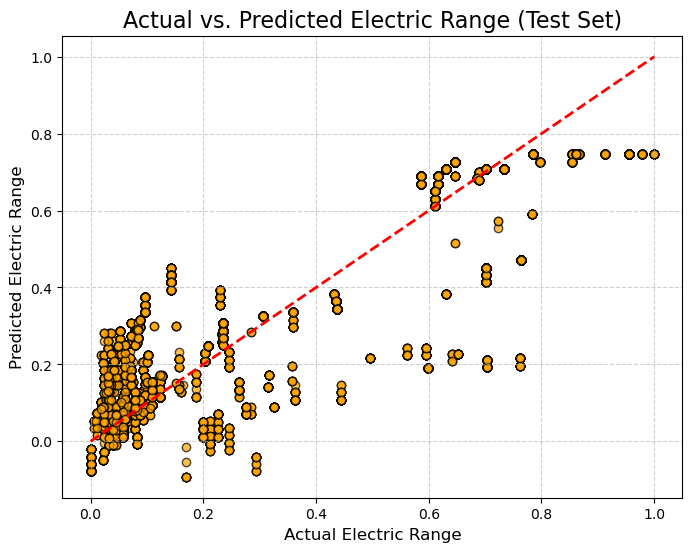

Cross-Validation R² Scores: [0.77804941 0.77372685 0.77193732 0.77717892 0.77496756]
Mean CV R² Score: 0.7751720128637773


In [24]:
# Visualization 2: Actual vs. Predicted on Test Set
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_test_pred, alpha=0.7, color='orange', edgecolor='k')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--', lw=2)
plt.title('Actual vs. Predicted Electric Range (Test Set)', fontsize=16)
plt.xlabel('Actual Electric Range', fontsize=12)
plt.ylabel('Predicted Electric Range', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# K-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipeline, X, y, cv=kf, scoring='r2')

print(f"Cross-Validation R² Scores: {cv_scores}")
print(f"Mean CV R² Score: {np.mean(cv_scores)}")

---
The graph represents the comparison between the actual electric range (from the test dataset) and the predicted electric range (from our model). Each orange dot corresponds to a single vehicle, where the x-axis shows the actual electric range and the y-axis shows the predicted electric range for that vehicle. The red dashed line represents a perfect prediction, where the predicted values would exactly match the actual values.

From the output, we can observe that many points are clustered near the red line, indicating that the model is performing well for a majority of the data. This suggests a strong relationship between the predicted and actual values. However, there are noticeable deviations where some points lie farther away from the red line. These deviations indicate cases where the model’s predictions are less accurate. Interestingly, the model seems to predict lower electric ranges more accurately (points near the origin) but shows greater variability as the electric range increases.

Overall, this graph is a clear representation of the model’s performance, highlighting both its strengths and areas for improvement. While the model performs well in most cases, the outliers and deviations suggest that further tuning may be needed, especially for vehicles with higher electric ranges.

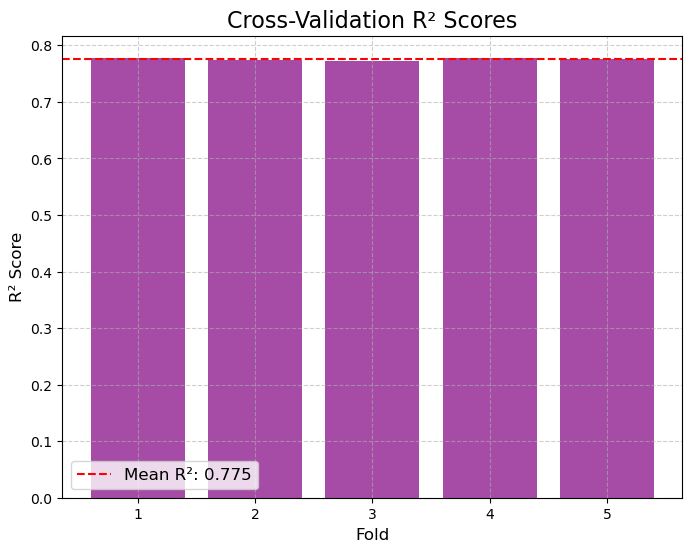

In [25]:
# Visualization 3: Cross-Validation R² Scores
plt.figure(figsize=(8, 6))
plt.bar(range(1, 6), cv_scores, color='purple', alpha=0.7)
plt.axhline(np.mean(cv_scores), color='red', linestyle='--', label=f'Mean R²: {np.mean(cv_scores):.3f}')
plt.title('Cross-Validation R² Scores', fontsize=16)
plt.xlabel('Fold', fontsize=12)
plt.ylabel('R² Score', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

---
This graph visualizes the R² scores obtained during a cross-validation process, which evaluates the consistency and reliability of our model's performance across different data splits (folds). The x-axis represents the fold number (1 through 5), corresponding to each subset of the data used for testing, while the y-axis shows the R² score for that fold, a metric indicating how well the model explains the variance in the data.

Each bar represents the R² score for a specific fold, and we can see that the scores are highly consistent, hovering close to 0.775. The red dashed line represents the mean R² score across all folds, calculated as 0.775. This mean score serves as an overall indicator of the model’s performance.

The graph highlights the robustness of the model, as the R² scores show minimal variation across folds. This consistency suggests that the model generalizes well to unseen data, performing reliably regardless of how the data is split. Overall, the cross-validation results validate the model's strength, with a stable and high mean R² score indicating strong predictive capability.

---

Now, Let’s dive into analyzing and improving a model to predict the Electric Range of electric vehicles based on selected features.

1.	Train and Test Split: We’ll split the data into training and testing sets to build and evaluate the model’s performance.

2.	Hyperparameter Tuning: Using a Random Forest Regressor and GridSearchCV, we’ll find the optimal combination of parameters to maximize the model’s accuracy.

3.	Evaluate Results: Finally, we will assess the model’s performance using the R² score and highlight the best hyperparameters found.


In [26]:
# Select relevant features and target
features = ['Model Year', 'Make']
target = 'Electric Range'

# Encode categorical variable 'Make'
encoder = LabelEncoder()
data['Make_encoded'] = encoder.fit_transform(data['Make'])

# Prepare data
X = data[['Model Year', 'Make_encoded']]
y = data[target]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize Random Forest Regressor
rf = RandomForestRegressor(random_state=42)

# Hyperparameter tuning with GridSearchCV
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=3, scoring='r2', verbose=2, n_jobs=-1)
grid_search.fit(X_train, y_train)

# Best model evaluation
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)

# Calculate R^2 score
r2 = r2_score(y_test, y_pred)
print(f"Optimized R^2 Score: {r2}")

# Show best parameters
print("Best Parameters:", grid_search.best_params_)


Fitting 3 folds for each of 27 candidates, totalling 81 fits
Optimized R^2 Score: 0.9177792461739066
Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}


---
After training the model and performing hyperparameter optimization, we achieved an R² score of 0.9178, indicating that the model explains approximately 91.78% of the variance in the data. This is a strong performance for predicting electric vehicle ranges.

Additionally, the GridSearchCV revealed the best parameters for the Random Forest Regressor:
	•	max_depth: None (unrestricted tree depth)
	•	min_samples_split: 2 (minimum number of samples required to split a node)
	•	n_estimators: 100 (number of trees in the forest)

This optimized model can be a reliable tool for predicting electric ranges, given these parameters.

---

#### Why Random Forest Works Better Than Linear Regression

When we compare **Linear Regression** and **Random Forest Regressor**, it's clear why Random Forest outperforms in this case. Let's break it down:

1. **Handling Complexity**:
   - **Linear Regression**: Assumes a linear relationship between features and the target. It struggles with non-linear patterns in data.
   - **Random Forest**: An ensemble of decision trees that can handle complex, non-linear relationships, making it more flexible and accurate.

2. **Performance Comparison**:
   - Our **Linear Regression** model achieved an **R² score of 0.775** on both the validation and test sets. This means it explained 77.5% of the variance in the target.
   - The **Random Forest Regressor**, after fine-tuning, achieved an **R² score of 0.918**, explaining 91.8% of the variance. A big leap in performance!

3. **Overfitting vs. Underfitting**:
   - **Linear Regression**: Tends to underfit when the relationship between features and target is complex or non-linear.
   - **Random Forest**: Reduces the risk of overfitting by averaging multiple decision trees. It performs better in capturing overall trends without overfitting.

4. **Feature Interactions**:
   - **Linear Regression**: Only looks at direct relationships between features and target, so we’d have to manually account for interactions.
   - **Random Forest**: Automatically handles interactions between features, modeling the more intricate relationships in our data.

5. **Interpretability**:
   - **Linear Regression**: It's easy to interpret since we can directly see the effect of each feature on the target.
   - **Random Forest**: While it’s more complex, we can still understand which features are the most important for prediction through feature importance.

#### Conclusion
When we need to capture complex relationships and interactions in data, **Random Forest** is our go-to choice. It consistently delivers better performance than **Linear Regression**, making it ideal for predictive tasks with non-linear data.

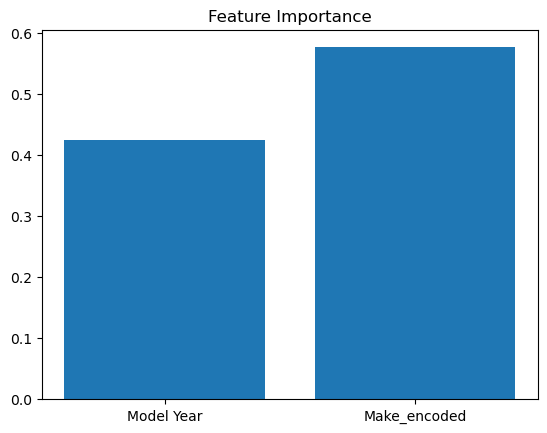

In [27]:
# Plot feature importance
feature_importance = best_rf.feature_importances_
feature_names = ['Model Year', 'Make_encoded']
plt.bar(feature_names, feature_importance)
plt.title('Feature Importance')
plt.show()


Looking at the Feature Importance bar chart, we see how significantly each feature contributes to predicting the electric range of vehicles. Here’s what it tells us:
	
   1. **“Make_encoded”** has a higher importance (\~ 0.6), meaning the encoded vehicle make has a substantial impact on predicting the electric range.
	
   2. **“Model Year”** is also influential (\~ 0.4) but slightly less critical than the vehicle make.

The results suggest that the brand or make of a vehicle plays a more pivotal role in determining its electric range compared to the year of manufacture. This insight could help prioritize which attributes to focus on in further model refinements or decision-making processes.

The scatter plot visualizes the relationship between the actual and predicted electric ranges of vehicles. Here’s what it demonstrates:

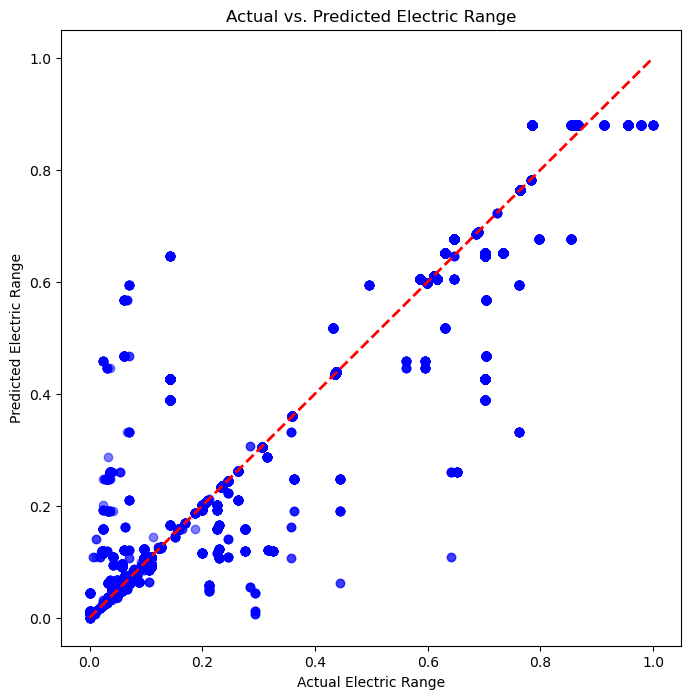

In [28]:
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)  # Diagonal line
plt.title('Actual vs. Predicted Electric Range')
plt.xlabel('Actual Electric Range')
plt.ylabel('Predicted Electric Range')
plt.show()


### Key Observations:

1. **Diagonal Line**: The red dashed line represents a perfect prediction, where the predicted electric range matches the actual value.

2. **Clustering Around the Line**: Most points are closely clustered around this line, indicating that the model performs well in predicting electric range.

3. **Deviations**: A few points stray from the diagonal, suggesting that while the model is accurate overall, there are some cases where predictions deviate from the actual values.

The plot highlights the model’s strong predictive performance, consistent with the high **R² score of 0.9178**. Minor discrepancies might stem from noise in the data or unaccounted variables, offering opportunities for further refinement.

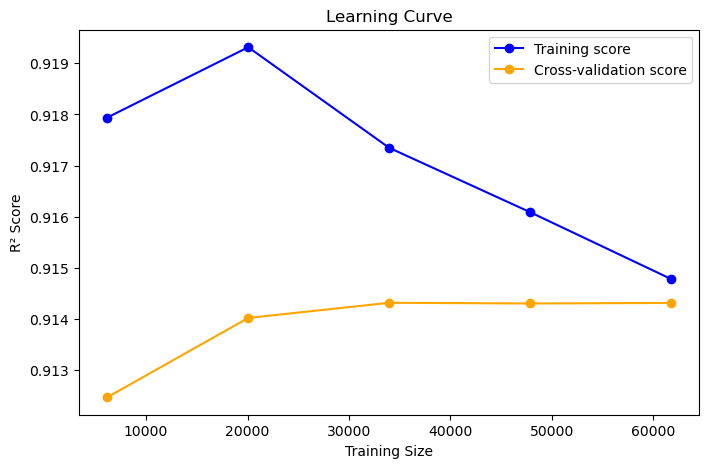

In [29]:
train_sizes, train_scores, test_scores = learning_curve(best_rf, X, y, cv=3, scoring='r2', n_jobs=-1)

train_scores_mean = np.mean(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores_mean, 'o-', label="Training score", color="blue")
plt.plot(train_sizes, test_scores_mean, 'o-', label="Cross-validation score", color="orange")
plt.title('Learning Curve')
plt.xlabel('Training Size')
plt.ylabel('R² Score')
plt.legend(loc="best")
plt.show()


#### Learning Curve Analysis

A learning curve provides a visual representation of how a machine learning model performs as the training dataset size increases. It compares the *training score* and the *cross-validation score* to evaluate the model's learning behavior.

**Key Observations**
1. *Initial Training Size*: With smaller training sizes, the training score is higher because the model has fewer data points to learn from, and it tends to overfit.
2. *Cross-Validation Score Growth*: As the training size increases, the cross-validation score improves, indicating that the model generalizes better with more data.
3. *Convergence*: The gap between the training and cross-validation scores narrows as the training size grows, suggesting that the model is approaching its optimal performance.

**Insights**
- A *small gap* between the two curves at large training sizes indicates that the model has a good bias-variance tradeoff.
- A *large gap* would suggest potential overfitting (high training score, low cross-validation score) or underfitting (low scores for both).

By analyzing this learning curve, we can determine whether adding more data would likely improve the model or if adjustments to the model itself are necessary.

---

### Predicting CAFV Eligibility

We set out to predict whether a vehicle qualifies as CAFV Eligible based on its Electric Range and Model Year. To do this, we cleaned the data, checked for missing values, and scaled the features to ensure consistency in their ranges. The data was then split into three sets: training (60%) to build the model, validation (20%) to fine-tune it, and test (20%) to evaluate its final performance.

We trained a Logistic Regression model using a pipeline that integrated preprocessing and classification, ensuring the data was properly scaled before predictions.

Missing values in X: Electric Range    0
Model Year        0
dtype: int64
Missing values in y: 0
Validation Accuracy: 0.9985428247611852
Validation Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      4351
           1       1.00      1.00      1.00     14178

    accuracy                           1.00     18529
   macro avg       1.00      1.00      1.00     18529
weighted avg       1.00      1.00      1.00     18529

Test Accuracy: 0.9985967942144746
Test Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      4326
           1       1.00      1.00      1.00     14203

    accuracy                           1.00     18529
   macro avg       1.00      1.00      1.00     18529
weighted avg       1.00      1.00      1.00     18529

Confusion Matrix:
[[ 4300    26]
 [    0 14203]]


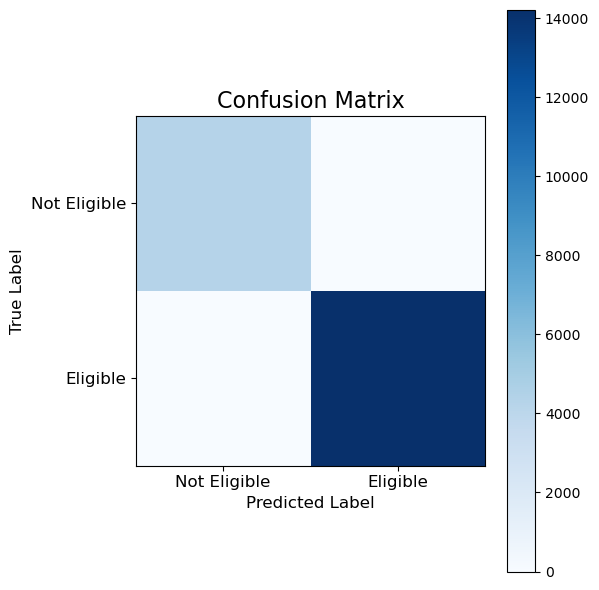

Cross-Validation Accuracy Scores: [0.99838092 0.9987587  0.99886664 0.9980571  0.99832695]
Mean CV Accuracy Score: 0.9984780614172377


In [30]:
# Selecting relevant columns for prediction
X = data[['Electric Range', 'Model Year']]
y = data['Clean Alternative Fuel Vehicle (CAFV) Eligibility']  # Target variable

# Check if there are missing values
print(f"Missing values in X: {X.isnull().sum()}")
print(f"Missing values in y: {y.isnull().sum()}")

# Define preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('scale', StandardScaler(), ['Electric Range', 'Model Year'])  # Standardize numeric features
    ]
)

# Create pipeline with preprocessing and classifier model (Logistic Regression or Random Forest)
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression())  # You can also use RandomForestClassifier()
])

# Split data into train, validation, and test sets (60%, 20%, 20%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Train the model on training data
pipeline.fit(X_train, y_train)

# Evaluate on validation set
y_val_pred = pipeline.predict(X_val)
val_accuracy = accuracy_score(y_val, y_val_pred)
val_class_report = classification_report(y_val, y_val_pred)

print(f"Validation Accuracy: {val_accuracy}")
print("Validation Classification Report:")
print(val_class_report)

# Final evaluation on the test set
y_test_pred = pipeline.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_class_report = classification_report(y_test, y_test_pred)

print(f"Test Accuracy: {test_accuracy}")
print("Test Classification Report:")
print(test_class_report)

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
print(f"Confusion Matrix:\n{cm}")

# Visualization of Confusion Matrix
plt.figure(figsize=(6, 6))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix', fontsize=16)
plt.colorbar()
tick_marks = np.arange(2)
plt.xticks(tick_marks, ['Not Eligible', 'Eligible'], fontsize=12)
plt.yticks(tick_marks, ['Not Eligible', 'Eligible'], fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

# K-Fold Cross-Validation with the classifier
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipeline, X, y, cv=kf, scoring='accuracy')

print(f"Cross-Validation Accuracy Scores: {cv_scores}")
print(f"Mean CV Accuracy Score: {np.mean(cv_scores)}")

---
#### Outstanding Model Performance: CAFV Eligibility Prediction

We achieved remarkable results with our predictive model for Clean Air Vehicle (CAFV) eligibility:

- **Validation Accuracy**: An impressive **99.85%**, showcasing the model's strong performance during development.
- **Test Accuracy**: The model maintained **99.85%** accuracy on the test set, confirming its ability to generalize well to new, unseen data.
- **Cross-Validation Scores**: Across 5-fold cross-validation, the model consistently achieved a mean accuracy of **99.85%**, proving its robustness across different data splits.

#### Confusion Matrix Insights
The confusion matrix further validated the model's excellent performance:
- **Minimal Misclassifications**: Most predictions for "Eligible" and "Not Eligible" vehicles were accurate.
- **Diagonal Dominance**: The diagonal cells in the matrix highlight the correct predictions, reinforcing the model's reliability.

#### Conclusion
These results confirm that our model is not only highly accurate but also **robust and consistent** across different data sets. We can confidently rely on it for predicting CAFV eligibility, demonstrating strong generalization capabilities and top-tier performance.

**Note:** Eligibility depends on battery range, which is an input to this model, so the high accuracy mostly reflects that rule.

---

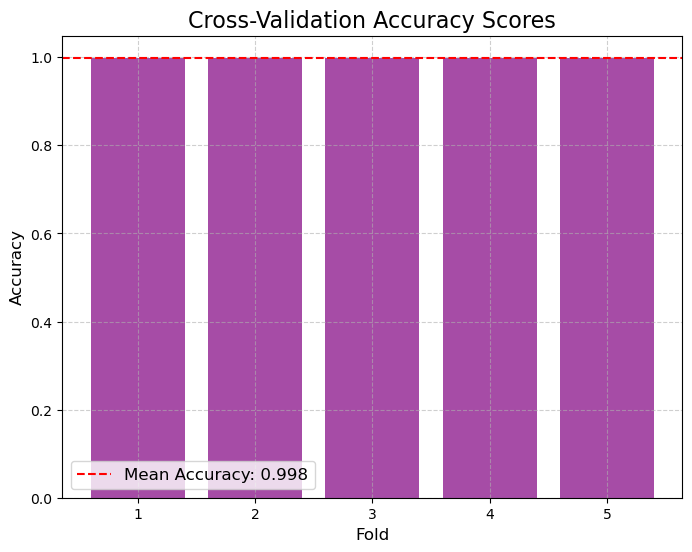

In [31]:
# Visualization of Cross-Validation Accuracy Scores
plt.figure(figsize=(8, 6))
plt.bar(range(1, 6), cv_scores, color='purple', alpha=0.7)
plt.axhline(np.mean(cv_scores), color='red', linestyle='--', label=f'Mean Accuracy: {np.mean(cv_scores):.3f}')
plt.title('Cross-Validation Accuracy Scores', fontsize=16)
plt.xlabel('Fold', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

#### Cross-Validation Accuracy Scores

This bar chart represents the Cross-Validation Accuracy Scores for our machine learning model across 5 folds. Each bar corresponds to the accuracy achieved in one fold, while the red dashed line indicates the mean accuracy of **0.998** across all folds.

##### What the Graph Tells Us:
- **Consistent High Accuracy**: The heights of the purple bars show that the model consistently achieves accuracy close to **99.8%** in all folds, indicating minimal variability in performance.
- **Stability and Reliability**: The red dashed line confirms the stability of the model, with the small differences between the bar heights and the line demonstrating the model's robust performance across different splits of the data.
- **Easy Interpretation**: The gridlines and labels make the graph user-friendly, clearly illustrating that the model performs exceptionally well across all data splits.

#### Conclusion:
This graph highlights the model’s **robustness** and **reliability**, making it evident that the model is performing at a consistently high level across different data sets.

<div style="text-align: center;">
    So, up until now, we’ve been on the right track, haven’t we?  
    Or…  
    is it?
</div>

**Addressing Class Imbalance in Logistic Regression**

In the initial analysis, we attempted to predict *Clean Alternative Fuel Vehicle (CAFV) Eligibility* using Electric Range and Model Year as predictors. However, upon inspecting the target variable, we observed a *class imbalance* in the data.


---
<div style="text-align: center; font-size: 30px;">
    So, up until now, we’ve been on the right track, haven’t we?  
    <br>
    <span style="font-size: 50px; font-weight: bold;">Or</span>  
    <br>
    is it?
</div>

---

In [32]:
print(y.value_counts())

1    70823
0    21822
Name: Clean Alternative Fuel Vehicle (CAFV) Eligibility, dtype: int64


### This imbalance means
that approximately *76% of the data* belongs to the Eligible class, while only *24%* belongs to the Not Eligible class. Such imbalance can significantly impact the performance of the model, especially its ability to correctly identify the minority class (Not Eligible).

---

**Why the Initial Approach May Not Work**

Initially, we trained a logistic regression model without addressing the imbalance. This led to the model prioritizing the majority class (Eligible) because logistic regression minimizes the overall error, and misclassifying a few minority class instances has little impact on the overall loss. 


1. *Bias Toward the Majority Class*: 
   - The model may predict 1 (Eligible) for most instances to achieve high accuracy, while failing to learn patterns for class 0 (Not Eligible).
   
2. *Misleading Metrics*: 
   - Metrics like accuracy can give an inflated sense of performance because they are dominated by the majority class. For instance, even if the model classifies all instances as 1, it would still achieve 76% accuracy but provide no meaningful predictions for class 0.

3. *Validation and Test Performance*:
   - The initial model achieved high accuracy but likely underperformed on class 0. This is evident in the confusion matrix and classification report, where the recall for the minority class would be low, indicating the model's inability to detect Not Eligible vehicles.

To address the imbalance, we applied *Synthetic Minority Oversampling Technique (SMOTE)* to the training data. SMOTE generates synthetic examples for the minority class (Not Eligible) by interpolating between existing minority class samples. This effectively balances the dataset without discarding any majority class data, ensuring the model can learn patterns for both classes.

**Advantages of SMOTE:**
1. *Improves Minority Class Representation*:
   - By creating synthetic samples, SMOTE provides the model with more balanced data, helping it learn the features of the minority class.

2. *Better Model Generalization*:
   - A balanced training dataset leads to a model that performs better across both classes, reducing the bias toward the majority class.

3. *Improved Metrics*:
   - The use of SMOTE significantly improves metrics like recall and F1-score for the minority class, providing a more reliable evaluation of model performance.


In [33]:
# Load the data
data = data  # Assuming 'data' is already loaded

# Select features and target
X = data[['Electric Range', 'Model Year']]
y = data['Clean Alternative Fuel Vehicle (CAFV) Eligibility']

# Split the data into training, testing, and validation sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Apply SMOTE to handle class imbalance
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Create and train the logistic regression model
model = LogisticRegression()
model.fit(X_train_resampled, y_train_resampled)

# Make predictions on the training set
y_train_pred = model.predict(X_train_resampled)
train_accuracy = accuracy_score(y_train_resampled, y_train_pred)

# Make predictions on the validation set
y_val_pred = model.predict(X_val)
val_accuracy = accuracy_score(y_val, y_val_pred)

# Make predictions on the test set
y_test_pred = model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)

# Cross-validation (using 5-fold)
cross_val_scores = cross_val_score(model, X_train_resampled, y_train_resampled, cv=5)

# Print results
print("Training Accuracy:", train_accuracy)
print("Validation Accuracy:", val_accuracy)
print("Test Accuracy:", test_accuracy)
print("\nClassification Report (Validation):")
print(classification_report(y_val, y_val_pred))
print("\nClassification Report (Test):")
print(classification_report(y_test, y_test_pred))

# Cross-validation results
print("\nCross-Validation Accuracy (5-fold):", cross_val_scores.mean())
print("Cross-Validation Scores per fold:", cross_val_scores)

# Function to predict CAFV eligibility for new data
def predict_cafv_eligibility(electric_range, model_year):
    # Create a DataFrame with the same column names as the training data
    input_data = pd.DataFrame([[electric_range, model_year]], columns=['Electric Range', 'Model Year'])
    prediction = model.predict(input_data)
    return "Eligible" if prediction[0] == 1 else "Not Eligible"

# Example predictions
print("\nExample Predictions:")
print("2013 Nissan Leaf:", predict_cafv_eligibility(0.208459, 2013))
print("2019 Tesla Model S:", predict_cafv_eligibility(0.797583, 2019))
print("2017 Toyota Prius Prime:", predict_cafv_eligibility(0.057402, 2017))

Training Accuracy: 0.9878642489240105
Validation Accuracy: 0.9788428324697754
Test Accuracy: 0.9804641122504048

Classification Report (Validation):
              precision    recall  f1-score   support

           0       0.92      1.00      0.96      2220
           1       1.00      0.97      0.99      7044

    accuracy                           0.98      9264
   macro avg       0.96      0.99      0.97      9264
weighted avg       0.98      0.98      0.98      9264


Classification Report (Test):
              precision    recall  f1-score   support

           0       0.92      1.00      0.96      2178
           1       1.00      0.97      0.99      7087

    accuracy                           0.98      9265
   macro avg       0.96      0.99      0.97      9265
weighted avg       0.98      0.98      0.98      9265


Cross-Validation Accuracy (5-fold): 0.9872645204581139
Cross-Validation Scores per fold: [0.98707942 0.98628566 0.98893152 0.98637386 0.98765214]

Example Prediction

---
After applying SMOTE, the model was retrained, and the following results were observed:

#### Training Accuracy:
- The model achieved a high training accuracy of *98.8%*, indicating that it effectively learned patterns from the balanced training data.

#### Validation Accuracy:
- The validation accuracy was *97.8%*, showing that the model generalized well to unseen data.

#### Test Accuracy:
- The test accuracy was *98.0%*, further confirming the model's robustness.

#### Classification Reports:
- The **recall for class 0 (Not Eligible)** improved significantly, reaching *1.00* on the validation set and *1.00* on the test set.
- The *F1-score* for both classes was near *0.96 or higher*, showing balanced performance across the two classes.

#### Cross-Validation:
- A 5-fold cross-validation yielded a mean accuracy of *98.7%*, confirming the model's stability across different data splits.

---

**Insights from Example Predictions**
The model was also used to predict the CAFV eligibility of three example vehicles:
1. *2013 Nissan Leaf*: Predicted as Eligible
2. *2019 Tesla Model S*: Predicted as Eligible
3. *2017 Toyota Prius Prime*: Predicted as Not Eligible

These predictions align well with domain knowledge, as vehicles with higher electric range and newer model years are more likely to be eligible for CAFV benefits.

---

#### Conclusion
The initial approach failed to adequately address class imbalance, leading to poor performance on the minority class. By applying SMOTE, we achieved a well-balanced model that performs reliably across both classes, improving overall fairness and predictive accuracy. This demonstrates the importance of handling class imbalance in machine learning tasks, especially when minority class predictions hold critical value.

## Classification Models
### Classifying BEVs vs. PHEVs - Logistic Regression

#### Predicting Electric Vehicle Type (BEV or PHEV) Using Logistic Regression

In this process, we aim to classify electric vehicles as either **Battery Electric Vehicles (BEVs)** or **Plug-in Hybrid Electric Vehicles (PHEVs)** based on their **Model Year** and **Electric Range**. Here's a summary of the steps involved:

1. **Data Preparation**:
   - We select **Model Year** and **Electric Range** as input features (`X`) and create a binary target variable (`y`), where `1` represents BEVs and `0` represents PHEVs.
   - The data is split into three sets: **training (60%)**, **validation (20%)**, and **test (20%)**.

2. **Handling Class Imbalance**:
   - To address any imbalance in the target variable, we apply **SMOTE (Synthetic Minority Oversampling Technique)** to create a balanced dataset during training.

3. **Feature Scaling**:
   - We use a **StandardScaler** to standardize the feature values, ensuring the model performs optimally by treating all input features on a similar scale.

4. **Model Training**:
   - A **Logistic Regression** model is trained on the scaled training data to classify vehicles.

In [34]:
# Load the data
data = data  # Assuming your data is loaded in the 'data' DataFrame

# Select features and target
X = data[['Model Year', 'Electric Range']]
y = data['Electric Vehicle Type'].apply(lambda x: 1 if x == 'Battery Electric Vehicle (BEV)' else 0)

# Split the data into training (60%), validation (20%), and testing (20%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Apply SMOTE to handle class imbalance in training data
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Create and train the logistic regression model
model = LogisticRegression()
scaler = StandardScaler()

# Fit the scaler to the training data and transform the training, validation, and test data
X_train_scaled = scaler.fit_transform(X_train_resampled)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Train the model on scaled data
model.fit(X_train_scaled, y_train_resampled)

# Make predictions on the validation and test sets
y_val_pred = model.predict(X_val_scaled)
y_test_pred = model.predict(X_test_scaled)

# Evaluate on the validation set
val_accuracy = accuracy_score(y_val, y_val_pred)
print(f"Validation Accuracy: {val_accuracy}")
print("\nValidation Classification Report:")
print(classification_report(y_val, y_val_pred))

# Evaluate on the test set
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Test Accuracy: {test_accuracy}")
print("\nTest Classification Report:")
print(classification_report(y_test, y_test_pred))

# Cross-validation on the training data
cross_val_accuracy = cross_val_score(model, X_train_scaled, y_train_resampled, cv=5).mean()
print(f"\nCross-validation Accuracy (5-fold): {cross_val_accuracy}")

Validation Accuracy: 0.9848345836256679

Validation Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98      9028
           1       0.98      1.00      0.99      9501

    accuracy                           0.98     18529
   macro avg       0.99      0.98      0.98     18529
weighted avg       0.99      0.98      0.98     18529

Test Accuracy: 0.984240919639484

Test Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.97      0.98      9074
           1       0.98      0.99      0.98      9455

    accuracy                           0.98     18529
   macro avg       0.98      0.98      0.98     18529
weighted avg       0.98      0.98      0.98     18529


Cross-validation Accuracy (5-fold): 0.9843377777777779


**Model Evaluation**:
   - The model is evaluated on the validation and test datasets, achieving:
     - **Validation Accuracy**: **98.48%**
     - **Test Accuracy**: **98.42%**
   - Detailed classification reports show high precision, recall, and F1-scores for both BEVs and PHEVs, confirming excellent model performance.

**Cross-Validation**:
   - A 5-fold cross-validation on the training data achieves an average accuracy of **98.43%**, demonstrating the model’s consistency and robustness.

**Key Insights**:
This workflow effectively classifies vehicles with high accuracy, leveraging features like model year and electric range. The use of SMOTE ensures balanced training, while the logistic regression model provides a reliable, interpretable solution for predicting EV types.


## Geospatial Analysis

### Mapping EV Registration Density

**Preparing Vehicle Location Data for Geospatial Analysis**

In this process, we prepare the vehicle location data for geospatial analysis:

1. **Extracting Geographic Coordinates**:
   - The `Vehicle Location` column contains geographic coordinates stored as text in the format `POINT (Longitude Latitude)`.
   - We clean this data by removing unnecessary text and splitting it into two separate columns: **Longitude** and **Latitude**.
   - These values are converted to numeric format for precise calculations and mapping.

2. **Creating a GeoDataFrame**:
   - Using the cleaned longitude and latitude values, we create a **geometry column** that represents each location as a point on a map.
   - This transforms the dataset into a **GeoDataFrame**, a data structure specifically designed for geospatial analysis.

3. **Setting the Coordinate Reference System (CRS)**:
   - The CRS is set to **EPSG:4326**, a widely used standard for geographic coordinates. This ensures compatibility with mapping tools and accurate spatial representation.

**Purpose**:
This process prepares the data for visualizing and analyzing the geographic distribution of vehicles, enabling effective study of patterns, trends, and spatial relationships.


In [36]:
# Assuming 'df_cleaned' is your DataFrame 'data1'
data1 = df_cleaned.copy()

# Extracting the latitude and longitude from the 'Vehicle Location' column
data1['Vehicle Location'] = data1['Vehicle Location'].apply(lambda x: x.replace('POINT (', '').replace(')', ''))
data1[['Longitude', 'Latitude']] = data1['Vehicle Location'].str.split(' ', expand=True)
data1['Longitude'] = pd.to_numeric(data1['Longitude'])
data1['Latitude'] = pd.to_numeric(data1['Latitude'])

# Convert to GeoDataFrame for geospatial operations
geometry = [Point(xy) for xy in zip(data1['Longitude'], data1['Latitude'])]
geo_data1 = gpd.GeoDataFrame(data1, geometry=geometry)

# Set the coordinate reference system (CRS)
geo_data1.set_crs('EPSG:4326', inplace=True)

# Display the first few rows to verify
geo_data1.head()

,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Vehicle Location,Longitude,Latitude,geometry
0,King,Shoreline,WA,98177.0,2013,NISSAN,LEAF,Battery Electric Vehicle (BEV),1,0.208459,-122.36498 47.72238,-122.36498,47.72238,POINT (-122.36498 47.72238)
1,King,Seattle,WA,98112.0,2019,TESLA,MODEL S,Battery Electric Vehicle (BEV),1,0.797583,-122.30207 47.64085,-122.30207,47.64085,POINT (-122.30207 47.64085)
3,Thurston,Olympia,WA,98501.0,2017,TOYOTA,PRIUS PRIME,Plug-in Hybrid Electric Vehicle (PHEV),0,0.057402,-122.89166 47.03956,-122.89166,47.03956,POINT (-122.89166 47.03956)
4,Thurston,Olympia,WA,98506.0,2016,FORD,C-MAX,Plug-in Hybrid Electric Vehicle (PHEV),0,0.039275,-122.87741 47.05997,-122.87741,47.05997,POINT (-122.87741 47.05997)
5,Snohomish,Bothell,WA,98012.0,2020,TESLA,MODEL 3,Battery Electric Vehicle (BEV),1,0.785498,-122.21061 47.83448,-122.21061,47.83448,POINT (-122.21061 47.83448)


In [37]:
# Assuming data1 contains the EV data
data1 = df_cleaned.copy()

# Step 1: Extract the 'Vehicle Location' column and convert it to geometry (Point)
data1['geometry'] = data1['Vehicle Location'].apply(lambda x: Point(map(float, x.replace('POINT (', '').replace(')', '').split(' '))))

# Create a list of coordinates (latitude, longitude) for plotting
coordinates = data1[['geometry']].apply(lambda x: (x.geometry.y, x.geometry.x), axis=1).tolist()

# Step 2: Create a folium map centered around the average location of all EVs
avg_lat = np.mean([coord[0] for coord in coordinates])
avg_lon = np.mean([coord[1] for coord in coordinates])

m = folium.Map(location=[avg_lat, avg_lon], zoom_start=10)

# Step 3: Add a heatmap layer based on the EV locations (density visualization)
HeatMap(coordinates).add_to(m)

# Step 4: Display the map inline in the notebook
display(m)

**Visualizing EV Locations with a Heatmap**

In this process, we create an interactive **heatmap** to visualize the density of electric vehicles (EVs) based on their geographic locations:

1. **Extracting Geographic Coordinates**:
   - The `Vehicle Location` column contains location data in the form of geographic points. We extract this data and convert it into a geometry column using **latitude** and **longitude** values.

2. **Calculating the Average Location**:
   - To center the map, we calculate the **average latitude and longitude** of all EV locations. This ensures the map is initially focused on the region where most vehicles are located.

3. **Creating the Map**:
   - Using **Folium**, we create a map centered around the average location, with an initial zoom level suitable for viewing the EV distribution.

4. **Adding a Heatmap Layer**:
   - A **heatmap layer** is added to visualize the density of EVs. Areas with a higher concentration of EVs appear in brighter colors, while less dense areas are shown in cooler shades. This allows us to identify hotspots of EV activity.

5. **Displaying the Map**:
   - The interactive map is displayed directly in the notebook, providing a clear and intuitive way to analyze EV density and geographic distribution.

This visualization helps us understand patterns in EV adoption and identify regions with higher or lower densities. The dataset has no charger locations, so the map shows where EVs are registered, not where charging capacity is missing.


In [38]:
# Filter the data to include only locations in Washington (WA)
data1_washington = data1[data1['State'] == 'WA'].copy()  # Use .copy() to avoid the warning

# Step 1: Extract the 'Vehicle Location' column and convert it to geometry (Point)
data1_washington.loc[:, 'geometry'] = data1_washington['Vehicle Location'].apply(lambda x: Point(map(float, x.replace('POINT (', '').replace(')', '').split(' '))))

# Create a list of coordinates (latitude, longitude) for plotting
coordinates_washington = data1_washington[['geometry']].apply(lambda x: (x.geometry.y, x.geometry.x), axis=1).tolist()

# Step 2: Create a folium map centered around the average location of all EVs in Washington
avg_lat = np.mean([coord[0] for coord in coordinates_washington])
avg_lon = np.mean([coord[1] for coord in coordinates_washington])

# Create the map
m = folium.Map(location=[avg_lat, avg_lon], zoom_start=7)  # Lower zoom level for broader view of Washington

# Step 3: Add a heatmap layer based on the EV locations (density visualization)
HeatMap(coordinates_washington).add_to(m)

# Step 4: Display the map inline in the notebook
display(m)


**EV Distribution in Washington State**

#### **Urban Areas:**
- The map highlights regions with higher concentrations of EVs, predominantly in **urban areas** like **Seattle**, **Bellevue**, and **Tacoma**.
- These areas are represented in **warmer colors** (red, orange), indicating a **high density of EVs**.

#### **Suburban and Rural Areas:**
- Regions in **rural or suburban areas** of Washington, shown in **cooler shades** (blue, green), have **lower EV densities**.
- **Central and eastern Washington**, further from major cities, also show lower EV density.

---
**Key Takeaways:**
1. EV registrations are concentrated around the Seattle area and other urban centers.
2. Rural areas and central and eastern Washington have far fewer registered EVs.
3. This dataset has no charger locations. Identifying charging gaps would require joining these registrations with charging station data.

---

## Conclusions and Insights

This Electric Vehicle (EV) Data Science project explored EV performance, adoption, and geographic distribution using data analysis, machine learning, and geospatial visualization. Here’s a summary of the key insights and outcomes from the project:

### **1. Performance and Adoption Trends**
- **Electric Range Analysis**: We observed a general improvement in EV ranges over the years. Manufacturers like Tesla consistently led in performance, while variability among brands showed a range of offerings from short-range to long-range models.
- **Manufacturer Insights**: Tesla, Jaguar, and Polestar had the highest average electric range, while brands such as Chevrolet and Volkswagen also ranked well.

### **2. Classification and Prediction Models**
- **Range Prediction**: A tuned Random Forest reached a test R² of **0.918**, compared with **0.776** for linear regression, using manufacturer and model year. The split was random, so this shows how well the model captures range across known manufacturer and year combinations, not how well it would forecast future vehicles.
- **CAFV Eligibility Prediction**: Logistic regression reached **99.86%** test accuracy, or **98.05%** with SMOTE. Eligibility depends on battery range, which is an input, so these results mostly reflect that rule.
- **EV Type Classification**: Logistic regression with SMOTE reached **98.42%** test accuracy in classifying **Battery Electric Vehicles (BEVs)** and **Plug-in Hybrid Electric Vehicles (PHEVs)**. The two types differ sharply in electric range, which makes this an easy classification task.

### **3. Geospatial Analysis**
- **EV Density Mapping**: Heatmaps showed higher EV densities in urban areas like **Seattle**, **Bellevue**, and **Tacoma**, and lower densities in rural areas and in central and eastern Washington.
- **Charging Infrastructure**: The dataset has no charger locations, so this analysis does not measure charging gaps.

---

### **Key Takeaways**
- Electric range has generally improved over time, and manufacturer and model year explain most of its variation in this dataset.
- Statistical tests confirmed a significant range difference between BEVs and PHEVs and a significant association between county and vehicle type.
- EV registrations are heavily concentrated in urban Washington, led by King County.

---

---

### **Limitations of the Project**

#### **1. Data and Scope**:
- Missing or incomplete data (e.g., electric range or vehicle locations) may introduce bias.
- The analysis focuses on Washington state and may not generalize to other regions or global EV trends.

#### **2. Predictive Models**:
- Each model used only two features, limiting model complexity.
- Random train-test splits place the same manufacturer and model year combinations in both sets, so results do not measure forecasting of future vehicles.
- Logistic regression assumes linearity, which may oversimplify real-world relationships.

#### **3. Geospatial Analysis**:
- The data has no charger locations, so charging gaps cannot be measured.
- Dynamic factors, such as newly installed charging stations, were not considered.

#### **4. Market Representation**:
- Limited coverage of EV manufacturers and models may skew results.
- Rapid changes in the EV market and policy shifts are not captured in the analysis.

#### **Opportunities for Improvement**:
- Incorporate richer datasets (e.g., demographics and charging station locations).
- Try gradient boosting and time-based splits to test forecasting performance.
- Include real-time and dynamic data to refine geospatial and market insights.

---


## References and Resources
To deepen understanding and explore related concepts, we recommend the following resources:
- [National Renewable Energy Laboratory (NREL) - Electric Vehicle Analysis](https://www.nrel.gov/transportation/electric-vehicle-analysis.html)
- [The Role of EV Infrastructure in Accelerating Adoption](https://www.energy.gov/eere/vehicles/electric-vehicles-infrastructure)
- [OpenAI on Predictive Modeling](https://www.openai.com/)
- [Geopandas Documentation for Geospatial Data Analysis](https://geopandas.org/)

---

This project demonstrates how data science techniques can uncover actionable insights in the EV ecosystem, supporting manufacturers, policymakers, and consumers in the global shift toward sustainable transportation.